# 01 · Exploratory analysis

Week-1 EDA on the 10% KKBox sample in `data/churn.duckdb`. Notebooks explore; `src/` decides, so nothing here is imported by the pipeline.

**Peeking rule:** every churn breakdown uses the **train** cohorts only. Validation and test cohorts stay unseen until model evaluation.

In [1]:
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

from churn.config import PROJECT_ROOT, get_settings

settings = get_settings()
con = duckdb.connect(str(settings.db_path), read_only=True)
FIG = PROJECT_ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


# Reference palette (validated): series 1 blue = retained, series 2 orange = churned.
RETAINED, CHURNED = "#2a78d6", "#eb6834"
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"]
)
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK_2,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.titlelocation": "left",
        "axes.titlesize": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "font.size": 10,
        "figure.dpi": 110,
        "savefig.bbox": "tight",
    }
)

## 1 · Cohort retention

Cohort = month of a user's first transaction. A user is *active* in a month if a paid membership covers any part of it. Jan-2015 is excluded because the transaction data starts then, so that 'cohort' is everyone already subscribed. Cancellations are ignored here, so retention is slightly optimistic.

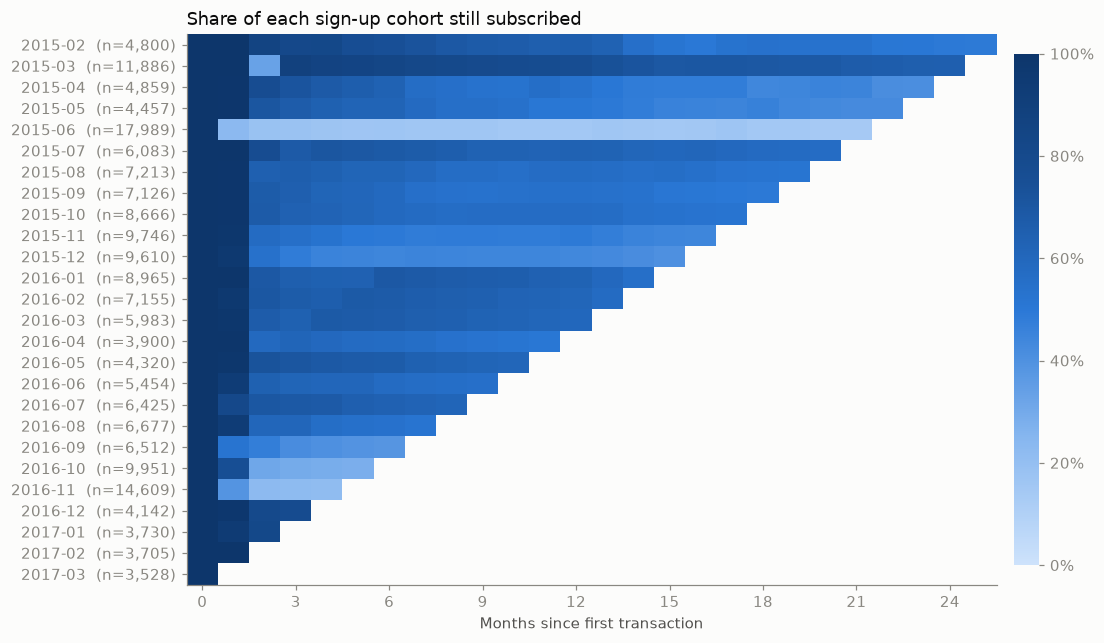

Average retention across cohorts: month 1: 89%, month 3: 60%, month 6: 59%, month 12: 55%


In [2]:
ret = q(f"""
WITH tx AS (
    SELECT msno,
           date_trunc('month', transaction_date)::DATE AS m0,
           date_trunc('month', least(membership_expire_date, DATE '{settings.data_end}'))::DATE
               AS m1
    FROM transactions
    WHERE NOT is_cancel AND membership_expire_date >= transaction_date
),
first AS (SELECT msno, min(m0) AS cohort FROM tx GROUP BY msno),
active AS (
    SELECT DISTINCT msno, unnest(generate_series(m0, m1, INTERVAL 1 MONTH))::DATE AS m FROM tx
)
SELECT f.cohort, date_diff('month', f.cohort, a.m) AS k, count(*) AS users
FROM first f JOIN active a USING (msno)
WHERE f.cohort >= DATE '2015-02-01'
GROUP BY ALL
""")
grid = ret.pivot_table(index="cohort", columns="k", values="users", aggfunc="sum").sort_index()
retention = grid.div(grid[0], axis=0)
sizes = grid[0].astype(int)

fig, ax = plt.subplots(figsize=(10, 6.5))
im = ax.imshow(retention.values, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
ax.grid(False)
ax.set_yticks(
    range(len(retention)),
    [f"{d:%Y-%m}  (n={n:,})" for d, n in zip(retention.index, sizes, strict=True)],
)
ax.set_xticks(range(0, retention.shape[1], 3))
ax.set_xlabel("Months since first transaction")
ax.set_title("Share of each sign-up cohort still subscribed", color=INK)
cb = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, format=lambda x, _: f"{x:.0%}")
cb.outline.set_visible(False)
fig.savefig(FIG / "cohort_retention.png")
plt.show()

curve = retention.mean().loc[[1, 3, 6, 12]]
print(
    "Average retention across cohorts:", ", ".join(f"month {k}: {v:.0%}" for k, v in curve.items())
)

## 2 · Churn rate by expiry cohort

All six labelled cohorts. Gap months are the embargo.

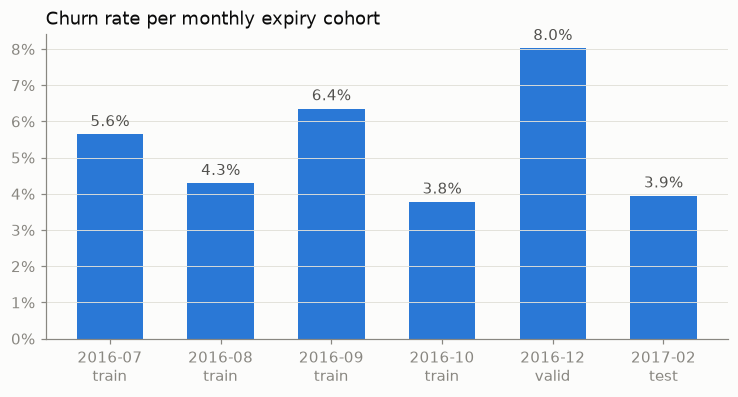

,cohort_month,split,users,churn_rate
0,2016-07-01,train,76896,0.056427
1,2016-08-01,train,80188,0.042924
2,2016-09-01,train,84727,0.063569
3,2016-10-01,train,83726,0.037790
4,2016-12-01,valid,88473,0.080217
5,2017-02-01,test,88109,0.039474


In [3]:
rates = q("""
SELECT cohort_month, split, count(*) AS users, avg(is_churn::INT) AS churn_rate
FROM labels GROUP BY ALL ORDER BY cohort_month
""")
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(rates))
ax.bar(x, rates.churn_rate, color=RETAINED, width=0.6)
ax.set_xticks(
    list(x), [f"{d:%Y-%m}\n{s}" for d, s in zip(rates.cohort_month, rates.split, strict=True)]
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="x", visible=False)
for i, r in rates.iterrows():
    ax.annotate(
        f"{r.churn_rate:.1%}",
        (i, r.churn_rate),
        ha="center",
        va="bottom",
        xytext=(0, 3),
        textcoords="offset points",
        color=INK_2,
    )
ax.set_title("Churn rate per monthly expiry cohort", color=INK)
fig.savefig(FIG / "churn_by_cohort.png")
plt.show()
rates

## 3 · Who churns? (train cohorts)

Membership state at the cutoff: the latest transaction before it. Tenure counts from the first transaction, and transactions start in Jan 2015, so it is capped at about 18–21 months.

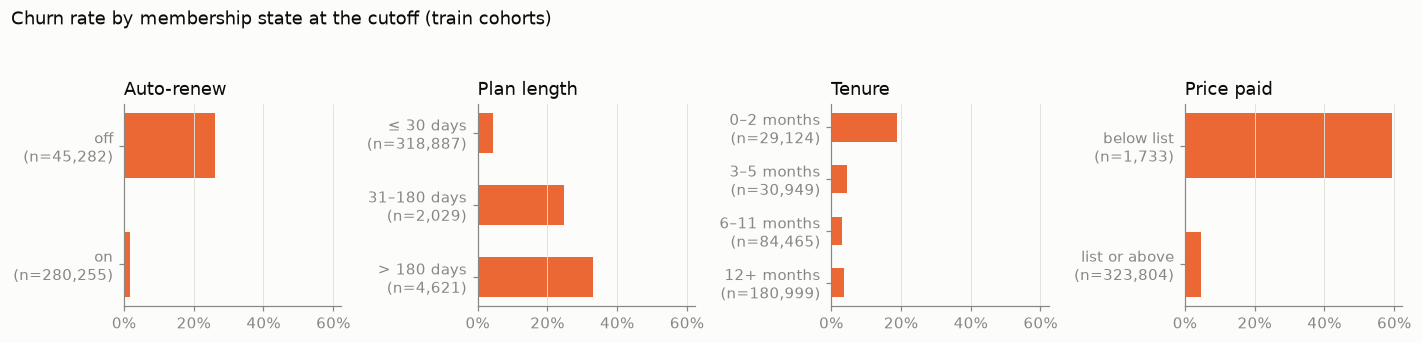

In [4]:
seg = q("""
WITH u AS (SELECT msno, cohort_month, is_churn FROM labels WHERE split = 'train'),
s AS (
    SELECT u.msno, u.cohort_month, u.is_churn, t.is_auto_renew, t.payment_plan_days,
           t.actual_amount_paid < t.plan_list_price AS discounted,
           date_diff('month', f.first_tx, u.cohort_month) AS tenure_m
    FROM u
    JOIN transactions t ON t.msno = u.msno AND t.transaction_date < u.cohort_month
    JOIN (SELECT msno, min(transaction_date) AS first_tx FROM transactions GROUP BY msno) f
      ON f.msno = u.msno
    QUALIFY row_number() OVER (
        PARTITION BY u.msno, u.cohort_month ORDER BY t.transaction_date DESC
    ) = 1
)
SELECT * FROM s
""")
seg["Auto-renew"] = seg.is_auto_renew.map({True: "on", False: "off"})
seg["Plan length"] = pd.cut(
    seg.payment_plan_days, [-1, 30, 180, 10_000], labels=["≤ 30 days", "31–180 days", "> 180 days"]
)
seg["Tenure"] = pd.cut(
    seg.tenure_m,
    [-1, 2, 5, 11, 100],
    labels=["0–2 months", "3–5 months", "6–11 months", "12+ months"],
)
seg["Price paid"] = seg.discounted.map({True: "below list", False: "list or above"})

dims = ["Auto-renew", "Plan length", "Tenure", "Price paid"]
fig, axes = plt.subplots(1, 4, figsize=(13, 2.9), sharex=True)
for ax, dim in zip(axes, dims, strict=True):
    g = seg.groupby(dim, observed=True).is_churn.agg(["mean", "size"])
    ax.barh(range(len(g)), g["mean"], color=CHURNED, height=0.55)
    ax.set_yticks(
        range(len(g)), [f"{i}\n(n={n:,})" for i, n in zip(g.index, g["size"], strict=True)]
    )
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.set_title(dim, color=INK)
fig.suptitle(
    "Churn rate by membership state at the cutoff (train cohorts)", x=0.01, ha="left", y=1.06
)
fig.tight_layout()
fig.savefig(FIG / "churn_by_segment.png")
plt.show()

pd.concat(
    {d: seg.groupby(d, observed=True).is_churn.agg(churn_rate="mean", users="size") for d in dims}
).style.format({"churn_rate": "{:.1%}", "users": "{:,}"})

## 4 · Listening before churn (train cohorts)

Average minutes listened per user per day, relative to the cohort cutoff. Days with no log count as zero. `total_secs` has corrupt values, so it is clipped to [0, 24h]. **Only the left of the dashed line is available to the model.**

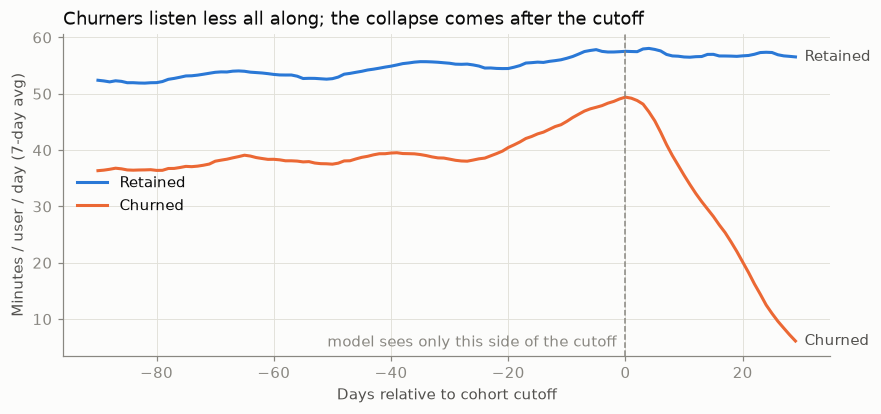

window,-90..-61,-60..-31,-30..-1,last30 / prior30
is_churn,,,,
retained,53.07,54.28,56.09,1.03
churned,37.51,38.55,43.98,1.14


In [5]:
listen = q("""
WITH u AS (SELECT msno, cohort_month, is_churn FROM labels WHERE split = 'train'),
n AS (SELECT is_churn, count(*) AS n FROM u GROUP BY ALL),
d AS (
    SELECT u.is_churn, date_diff('day', u.cohort_month, l.date) AS day,
           sum(least(greatest(l.total_secs, 0), 86400)) AS secs
    FROM u JOIN user_logs l
      ON l.msno = u.msno AND l.date >= u.cohort_month - 90 AND l.date < u.cohort_month + 30
    GROUP BY ALL
)
SELECT d.is_churn, d.day, d.secs / n.n / 60 AS minutes FROM d JOIN n USING (is_churn)
ORDER BY 1, 2
""")
fig, ax = plt.subplots(figsize=(9, 3.8))
for churn, color, name in [(False, RETAINED, "Retained"), (True, CHURNED, "Churned")]:
    s = listen[listen.is_churn == churn].set_index("day").minutes.rolling(7, min_periods=1).mean()
    ax.plot(s.index, s.to_numpy(), color=color, lw=2, label=name)
    ax.annotate(
        name,
        (s.index[-1], s.to_numpy()[-1]),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        color=INK_2,
    )
ax.axvline(0, color=MUTED, ls="--", lw=1)
ax.annotate(
    "model sees only this side of the cutoff",
    (0, ax.get_ylim()[0]),
    xytext=(-6, 6),
    textcoords="offset points",
    ha="right",
    color=MUTED,
)
ax.set_xlabel("Days relative to cohort cutoff")
ax.set_ylabel("Minutes / user / day (7-day avg)")
ax.legend(frameon=False, loc="center left")
ax.set_title("Churners listen less all along; the collapse comes after the cutoff", color=INK)
fig.savefig(FIG / "listening_before_churn.png")
plt.show()

w = listen.assign(
    window=pd.cut(listen.day, [-91, -61, -31, -1], labels=["-90..-61", "-60..-31", "-30..-1"])
)
trend = w.dropna(subset=["window"]).pivot_table(
    index="is_churn", columns="window", values="minutes", aggfunc="mean", observed=True
)
trend["last30 / prior30"] = trend["-30..-1"] / trend["-60..-31"]
trend.rename(index={False: "retained", True: "churned"}).round(2)

## 5 · Missingness and data quality (train cohorts)

In [6]:
quality = q("""
WITH u AS (SELECT DISTINCT msno FROM labels WHERE split = 'train')
SELECT
    avg((m.msno IS NULL)::INT)                                        AS no_member_row,
    avg((m.gender IS NULL)::INT)                                      AS gender_missing,
    avg((m.bd IS NULL OR m.bd NOT BETWEEN 10 AND 80)::INT)            AS age_missing_or_implausible,
    avg((m.registration_date IS NULL)::INT)                           AS registration_missing,
    avg((NOT EXISTS (SELECT 1 FROM user_logs l WHERE l.msno = u.msno))::INT) AS no_listening_logs
FROM u LEFT JOIN members m USING (msno)
""").T.rename(columns={0: "share of train users"})
bad_secs = q("SELECT avg((total_secs NOT BETWEEN 0 AND 86400)::INT) AS v FROM user_logs").v[0]
print(f"user_logs rows with total_secs outside [0, 24h]: {bad_secs:.2%}")
quality.style.format("{:.1%}")

user_logs rows with total_secs outside [0, 24h]: 0.03%


,share of train users
no_member_row,11.8%
gender_missing,58.8%
age_missing_or_implausible,59.0%
registration_missing,11.8%
no_listening_logs,15.3%


## Takeaways

1. **Churn is front-loaded.** Across sign-up cohorts, about 89% are still subscribed after 1 month and about 60% after 3. The curve then flattens to about 55% at 12 months: survivors are sticky. A few large cohorts (2015-06, 2016-09 to 2016-11) lose most users after month 1. That pattern fits promotional sign-ups, but it is a hypothesis and has not been checked.
2. **The base rate moves.** Cohort churn ranges from 3.8% to 8.0%. Validation (Dec, 8.0%) is twice the test month (Feb, 3.9%). Probabilities calibrated on validation will likely run high on test. Week 2 must measure calibration on test, not assume it carries over.
3. **Auto-renew dominates.** Churn is 26.1% with auto-renew off versus 1.6% with it on, and 86% of users have it on. The real ranking problem is among auto-renew-off and new users. Other strong cuts: paid below list price 59% (n = 1,735), plans over 30 days 25–33%, and tenure of 0–2 months 19%.
4. **Listening level separates the groups; pre-cutoff trend does not.** Churners listen about 30% less than retained users across the whole 90 days (38 vs 54 min/day). Their last-30 vs prior-30 ratio actually *rises* (×1.14 vs ×1.03). The dramatic decay happens after the cutoff, so any feature that touched post-cutoff logs would look spectacular and be pure leakage. Week 2 should still try trend features, but expect level features to carry more weight. The leakage test is essential.
5. **Missingness is structural.** 11.8% of users have no member row. Gender and age are missing or implausible for about 59% (age 0 is a placeholder), so they need missing-indicator treatment, not imputation. 15.3% have no listening logs at all, and 'no logs' must be a feature, not a reason to drop rows. Only 0.03% of `total_secs` values are corrupt; clipping handles them.